# Solar filaments: native 2048 × 2048 U-Net

Train on **complete images** and predict each image in a single forward pass,
keeping narrow filaments at their original pixel resolution. This is a separate experiment from
`solar-filament-u-net.ipynb`; its tiled baseline is preserved.

The full-image U-Net uses seven downsampling stages (2048 → 16), a full-resolution
skip connection, and a small global-context branch. Width starts at 16 channels
and is capped at 256. Extra depth expands context; narrow early layers control
the activation memory cost. GroupNorm supports small batches without running
statistics, and activation checkpointing trades extra computation for memory.

Target: **2 GPUs with 14 GiB each, 30 GB host RAM, four total loader workers**.
DDP trains a replica on each GPU using different **whole images**; GPU memories
are separate. FP16 AMP, a real forward/backward/Adam memory probe, and gradient
accumulation make this practical without assuming a measured VRAM requirement.

Thin-structure safeguards: no resizing or crop training, pixel-preserving flips
and 90° rotations, full-resolution skips, and thresholding/component extraction
only after a complete-image prediction. The component-area filter defaults to
one pixel. Validation must decide whether larger filtering improves quality.
These choices remove artificial tile seams; they do not guarantee connectivity
or resolve two distinct filaments that touch in a binary union mask.


In [1]:
%pip install -q pycocotools scikit-learn pandas matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[variable] = "1"
import csv
import gc
import hashlib
import importlib.util
import json
import signal
import subprocess
import sys
import time
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from pycocotools import mask as mask_utils
from sklearn.model_selection import train_test_split

cv2.setNumThreads(1)
torch.set_num_threads(1)
DATA_ROOT_OVERRIDE = None
ANNOTATION_FILENAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
IMAGE_SIZE = 2048
RANDOM_SEED = 10

def is_dataset_root(path):
    return ((path / "train" / "train_images").is_dir()
            and (path / "train" / ANNOTATION_FILENAME).is_file()
            and (path / "test" / "test_images").is_dir())

def find_dataset_root():
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidates.extend((parent, parent / "MAGFilo_1.0_Kaggle_2026",
                           parent / "MAGFiLO_1.0_Kaggle_2026"))
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        candidates.extend(p.parent.parent for p in kaggle.rglob(ANNOTATION_FILENAME))
    for candidate in candidates:
        if is_dataset_root(candidate):
            return candidate.resolve()
    raise FileNotFoundError("Set DATA_ROOT_OVERRIDE to the folder containing train/ and test/.")

DATA_ROOT = (Path(DATA_ROOT_OVERRIDE).expanduser().resolve()
             if DATA_ROOT_OVERRIDE else find_dataset_root())
if not is_dataset_root(DATA_ROOT):
    raise FileNotFoundError(f"Invalid dataset root: {DATA_ROOT}")
TRAIN_IMAGES_DIR = DATA_ROOT / "train" / "train_images"
TEST_IMAGES_DIR = DATA_ROOT / "test" / "test_images"
ANNOTATION_PATH = DATA_ROOT / "train" / ANNOTATION_FILENAME
OUTPUT_DIR = Path.cwd() / "unet_full_image_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "full_image_unet_best.pth"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
SUBMISSION_PATH = OUTPUT_DIR / "solar_filament_full_image_submission.csv"
print(f"Dataset: {DATA_ROOT}")


Dataset: D:\filament-segmentation-2026\MAGFilo_1.0_Kaggle_2026


## Keep source files separated between training and validation

Use the baseline's split: multi-annotator source files stay in training, and
validation contains only single-annotator files. Each annotator record remains
an individual training example. This preserves the existing label policy for
comparison, including its extra weight on multiply annotated sources.


In [3]:
annotation_bytes = ANNOTATION_PATH.read_bytes()
annotations = json.loads(annotation_bytes)
image_by_id = {item["id"]: item for item in annotations["images"]}
annotations_by_image = defaultdict(list)
for annotation in annotations["annotations"]:
    annotations_by_image[annotation["image_id"]].append(annotation)
name_to_image_ids = defaultdict(list)
for item in annotations["images"]:
    if (int(item["height"]), int(item["width"])) != (IMAGE_SIZE, IMAGE_SIZE):
        raise ValueError(f"Expected native 2048-square annotations: {item['file_name']}")
    name_to_image_ids[item["file_name"]].append(item["id"])

single_ids = [ids[0] for ids in name_to_image_ids.values() if len(ids) == 1]
multi_ids = [image_id for ids in name_to_image_ids.values() if len(ids) > 1 for image_id in ids]
if len(single_ids) < 2:
    raise ValueError("At least two single-annotator images are required.")
val_count = min(max(1, round(0.2 * len(name_to_image_ids))), len(single_ids) - 1)
train_single_ids, val_image_ids = train_test_split(
    single_ids, test_size=val_count, random_state=RANDOM_SEED, shuffle=True)
train_image_ids = train_single_ids + multi_ids
train_files = {image_by_id[i]["file_name"] for i in train_image_ids}
val_files = {image_by_id[i]["file_name"] for i in val_image_ids}
assert not train_files.intersection(val_files), "Source-image leakage"
print(f"Train: {len(train_image_ids)} records / {len(train_files)} source files")
print(f"Validation: {len(val_image_ids)} complete images")

def polygons_to_mask(image_id):
    info = image_by_id[image_id]
    mask = np.zeros((int(info["height"]), int(info["width"])), dtype=np.uint8)
    for annotation in annotations_by_image[image_id]:
        segmentation = annotation["segmentation"]
        if isinstance(segmentation, dict):
            rle = segmentation
            if isinstance(rle["counts"], list):
                rle = mask_utils.frPyObjects(rle, *mask.shape)
            decoded = mask_utils.decode(rle)
            if decoded.ndim == 3:
                decoded = decoded.any(axis=2)
            mask |= (decoded > 0).astype(np.uint8)
        else:
            for polygon in segmentation:
                points = np.asarray(polygon, dtype=np.float32).reshape(-1, 2)
                if len(points) >= 3:
                    cv2.fillPoly(mask, [np.round(points).astype(np.int32)], 1)
    return mask


Train: 1013 records / 566 source files
Validation: 141 complete images


## Stream complete masks to disk

Read original grayscale images on demand and cache only compressed uint8 masks.
No tile cache or per-process copy of the entire dataset is created. With four
training workers, prefetch factor one, and batch one or two, queued image/mask
arrays remain small relative to 30 GB RAM. CPU decoding and storage speed may
still limit GPU utilization; the runtime reports image throughput and peak VRAM.


In [4]:
mask_fingerprint = hashlib.sha256(annotation_bytes + b"full-image-cv2-union-v1").hexdigest()[:16]
MASK_DIR = OUTPUT_DIR / "masks" / mask_fingerprint
MASK_DIR.mkdir(parents=True, exist_ok=True)

def make_records(image_ids):
    records = []
    for index, image_id in enumerate(image_ids, start=1):
        info = image_by_id[image_id]
        image_path = (TRAIN_IMAGES_DIR / info["file_name"]).resolve()
        with Image.open(image_path) as opened:
            if opened.size != (IMAGE_SIZE, IMAGE_SIZE):
                raise ValueError(f"Image is not native 2048-square: {image_path}")
        safe_name = hashlib.sha256(str(image_id).encode()).hexdigest()
        mask_path = (MASK_DIR / f"{safe_name}.png").resolve()
        if not mask_path.exists():
            if not cv2.imwrite(str(mask_path), polygons_to_mask(image_id) * 255):
                raise OSError(f"Cannot write mask: {mask_path}")
        records.append(dict(image_path=str(image_path), mask_path=str(mask_path),
                            image_id=image_id, file_name=info["file_name"]))
        if index % 100 == 0 or index == len(image_ids):
            print(f"Prepared {index}/{len(image_ids)} full-image records", flush=True)
    return records

train_records = make_records(train_image_ids)
val_records = make_records(val_image_ids)
(OUTPUT_DIR / "split_manifest.json").write_text(
    json.dumps(dict(train=train_records, val=val_records, image_size=IMAGE_SIZE), indent=2),
    encoding="utf-8")


Prepared 100/1013 full-image records
Prepared 200/1013 full-image records
Prepared 300/1013 full-image records
Prepared 400/1013 full-image records
Prepared 500/1013 full-image records
Prepared 600/1013 full-image records
Prepared 700/1013 full-image records
Prepared 800/1013 full-image records
Prepared 900/1013 full-image records
Prepared 1000/1013 full-image records
Prepared 1013/1013 full-image records
Prepared 100/141 full-image records
Prepared 141/141 full-image records


458194

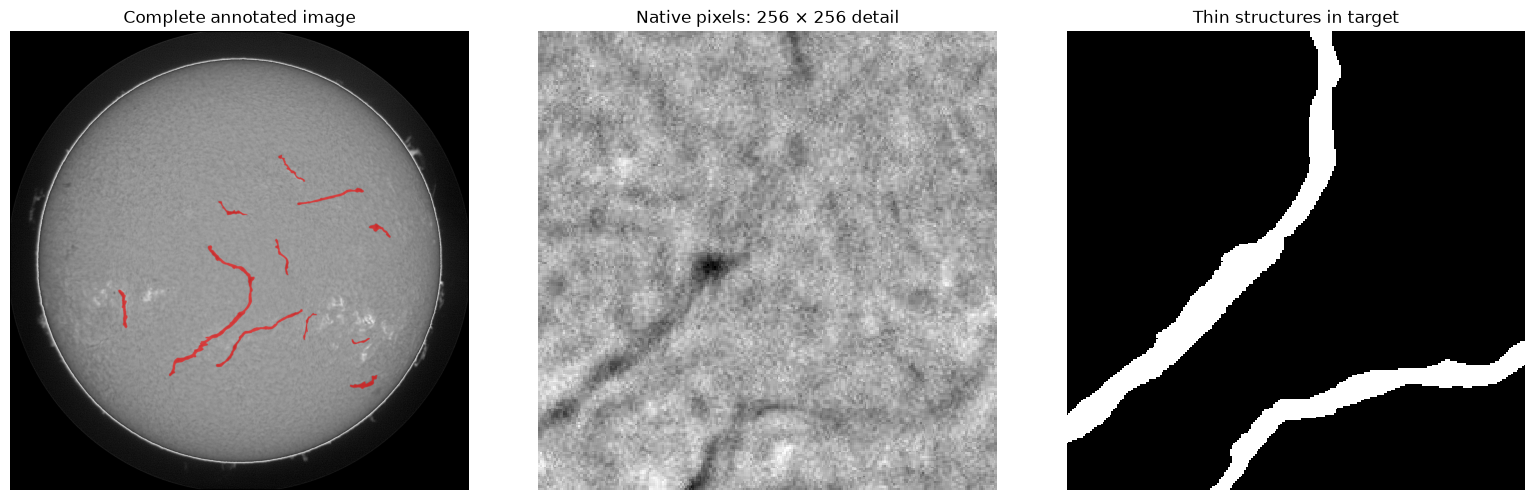

In [5]:
# Inspect native detail as well as the complete image. This crop is visualization only.
sample = val_records[0]
sample_image = cv2.imread(sample["image_path"], cv2.IMREAD_GRAYSCALE)
sample_mask = cv2.imread(sample["mask_path"], cv2.IMREAD_GRAYSCALE) > 127
ys, xs = np.where(sample_mask)
cy, cx = ((int(np.median(ys)), int(np.median(xs))) if len(ys) else (1024, 1024))
y0, x0 = min(max(cy - 128, 0), IMAGE_SIZE - 256), min(max(cx - 128, 0), IMAGE_SIZE - 256)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(sample_image, cmap="gray")
axes[0].imshow(np.ma.masked_where(~sample_mask, sample_mask), cmap="autumn", alpha=0.6)
axes[0].set_title("Complete annotated image")
axes[1].imshow(sample_image[y0:y0+256, x0:x0+256], cmap="gray", interpolation="nearest")
axes[1].set_title("Native pixels: 256 × 256 detail")
axes[2].imshow(sample_mask[y0:y0+256, x0:x0+256], cmap="gray", interpolation="nearest")
axes[2].set_title("Thin structures in target")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()
del sample_image, sample_mask, ys, xs


## Training settings and memory probe

Start with base width 16, depth 7, FP16, and checkpointing. The GPU probe tries
microbatches 1 through 4 using real backward and optimizer steps, restores initial
weights/RNG, and chooses the fastest common fit with reserved-memory headroom.
It does not combine the GPUs' VRAM. Leave additional headroom if other processes
use the GPUs. A startup probe reduces OOM risk; the target run must still verify
actual training peaks. To recover from OOM, first set `PER_GPU_BATCH_SIZE = 1`;
if necessary set `BASE_CHANNELS = 8`. Keep the native image resolution.

Effective batch = microbatch × GPU count × accumulation steps (8 at batch one,
two GPUs, accumulation four). Dice is computed for each distributed microbatch;
accumulating gradients does not turn it into a single Dice over all eight images.
Epoch checkpoint selection retains the baseline's combined loss with hard Dice;
it is a pixel/union objective, not a connectivity or exact instance-PQ objective.

GroupNorm and global-context features couple distant regions, while decoder
skips retain native detail. Additional layers alone do not restore missing fine
features. Inspect the native-detail validation plots and complete-image metrics
before claiming an improvement over the tiled model.


In [6]:
BASE_CHANNELS = 16
DEPTH = 7
MAX_CHANNELS = 256
PER_GPU_BATCH_SIZE = "auto"     # Probe 1 through 4; set integer 1 for a conservative run.
GRADIENT_ACCUMULATION_STEPS = 4
NUM_WORKERS = 4                # TOTAL: two per rank with two GPUs.
PREFETCH_FACTOR = 1
MEMORY_FRACTION = 0.85
NUM_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
LOSS_WEIGHTS = {"log_soft_pq": 0.4, "dice": 0.4, "bce": 0.2}
AMP_ENABLED = True
USE_CHANNELS_LAST = True
NUM_GPUS = min(2, torch.cuda.device_count())
if not torch.cuda.is_available():
    raise RuntimeError("Select a CUDA-enabled PyTorch kernel or Kaggle GPU accelerator.")
if NUM_GPUS > 1 and not sys.platform.startswith("linux"):
    raise RuntimeError("The two-GPU NCCL training path requires Linux/Kaggle. A single GPU can smoke-test locally.")
DEVICE = torch.device("cuda:0")
for index in range(NUM_GPUS):
    properties = torch.cuda.get_device_properties(index)
    print(f"GPU {index}: {properties.name}, {properties.total_memory / 2**30:.2f} GiB")
print(f"{NUM_GPUS} GPU(s); {NUM_WORKERS} total workers; no resize or tiling")


GPU 0: NVIDIA GeForce RTX 3070 Ti Laptop GPU, 8.00 GiB
1 GPU(s); 4 total workers; no resize or tiling


In [7]:
# Embedded worker: this notebook can be uploaded to Kaggle on its own.
FULL_IMAGE_RUNTIME_SOURCE = '"""Native-resolution U-Net worker; launched with torchrun from the full-image notebook.\n\nNo tiles or spatial resampling are used. DDP replicates the model on each GPU;\nit does not combine the cards into one larger VRAM pool.\n"""\nimport argparse\nfrom contextlib import nullcontext\nimport csv\nimport gc\nimport json\nimport math\nimport os\nimport random\nimport time\nfrom datetime import timedelta\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\nimport torch\nimport torch.distributed as dist\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom torch.nn.parallel import DistributedDataParallel\nfrom torch.utils.checkpoint import checkpoint\nfrom torch.utils.data import DataLoader, Dataset, DistributedSampler\n\n\nclass DoubleConv(nn.Module):\n    def __init__(self, in_channels, out_channels, dilation=1):\n        super().__init__()\n        groups = math.gcd(8, out_channels)\n        self.layers = nn.Sequential(\n            nn.Conv2d(in_channels, out_channels, 3, padding=dilation,\n                      dilation=dilation, bias=False),\n            nn.GroupNorm(groups, out_channels), nn.ReLU(inplace=False),\n            nn.Conv2d(out_channels, out_channels, 3, padding=dilation,\n                      dilation=dilation, bias=False),\n            nn.GroupNorm(groups, out_channels), nn.ReLU(inplace=False),\n        )\n\n    def forward(self, inputs):\n        return self.layers(inputs)\n\n\nclass GlobalContext(nn.Module):\n    """A pooled image summary makes every output depend on the complete input."""\n    def __init__(self, channels):\n        super().__init__()\n        self.local = DoubleConv(channels, channels, dilation=2)\n        self.global_projection = nn.Conv2d(channels, channels, 1)\n\n    def forward(self, inputs):\n        local = self.local(inputs)\n        return local + self.global_projection(F.adaptive_avg_pool2d(local, 1))\n\n\nclass DecoderStage(nn.Module):\n    def __init__(self, in_channels, skip_channels):\n        super().__init__()\n        self.up = nn.ConvTranspose2d(in_channels, skip_channels, 2, stride=2)\n        self.conv = DoubleConv(skip_channels * 2, skip_channels)\n\n    def forward(self, inputs, skip):\n        return self.conv(torch.cat((self.up(inputs), skip), dim=1))\n\n\nclass FullImageUNet(nn.Module):\n    def __init__(self, in_channels=1, out_channels=1, base_channels=16,\n                 depth=7, max_channels=256, checkpoint_blocks=True):\n        super().__init__()\n        if min(in_channels, out_channels, base_channels, depth, max_channels) < 1:\n            raise ValueError(\'Channel counts and depth must be positive integers.\')\n        self.depth = int(depth)\n        self.image_size = 2048\n        self.checkpoint_blocks = bool(checkpoint_blocks)\n        channels = [min(base_channels * 2**index, max_channels)\n                    for index in range(self.depth + 1)]\n        self.encoders = nn.ModuleList()\n        current = in_channels\n        for channel in channels[:-1]:\n            self.encoders.append(DoubleConv(current, channel))\n            current = channel\n        self.bottleneck = nn.Sequential(DoubleConv(current, channels[-1]),\n                                        GlobalContext(channels[-1]))\n        self.decoders = nn.ModuleList()\n        current = channels[-1]\n        for channel in reversed(channels[:-1]):\n            self.decoders.append(DecoderStage(current, channel))\n            current = channel\n        self.output = nn.Conv2d(current, out_channels, 1)\n\n    def _block(self, block, *inputs):\n        if self.checkpoint_blocks and self.training and torch.is_grad_enabled():\n            # Checkpointing the complete decoder stage also releases up/cat tensors.\n            return checkpoint(block, *inputs, use_reentrant=False)\n        return block(*inputs)\n\n    def forward(self, inputs):\n        divisor = 2**self.depth\n        if inputs.ndim != 4 or min(inputs.shape[-2:]) < divisor or any(\n                size % divisor for size in inputs.shape[-2:]):\n            raise ValueError(f\'Input must be BCHW, with H and W divisible by {divisor}.\')\n        skips = []\n        for encoder in self.encoders:\n            inputs = self._block(encoder, inputs)\n            skips.append(inputs)\n            inputs = F.max_pool2d(inputs, 2)\n        inputs = self._block(self.bottleneck, inputs)\n        for decoder, skip in zip(self.decoders, reversed(skips)):\n            inputs = self._block(decoder, inputs, skip)\n        return self.output(inputs)\n\n\nDEFAULT_LOSS_WEIGHTS = {\'log_soft_pq\': 0.4, \'dice\': 0.4, \'bce\': 0.2}\n\n\ndef validate_loss_weights(weights):\n    if set(weights) != set(DEFAULT_LOSS_WEIGHTS):\n        raise ValueError(f\'loss_weights must contain exactly {tuple(DEFAULT_LOSS_WEIGHTS)}\')\n    weights = {name: float(value) for name, value in weights.items()}\n    if any(not np.isfinite(value) or value < 0 for value in weights.values()):\n        raise ValueError(\'Loss weights must be finite and nonnegative.\')\n    if not np.isclose(sum(weights.values()), 1.0):\n        raise ValueError(\'Loss weights must sum to 1.\')\n    return weights\n\n\ndef segmentation_loss(logits, targets, weights=None, sync_dice=False, smooth=1.0):\n    """Original union-PQ surrogate, global foreground Dice and pixel BCE.\n\n    This is a semantic union-mask surrogate, not true instance panoptic quality.\n    sync_dice pools each microbatch across ranks. Accumulation averages these\n    microbatch Dice objectives; it is not Dice over the entire effective batch.\n    """\n    weights = DEFAULT_LOSS_WEIGHTS if weights is None else weights\n    with torch.autocast(device_type=logits.device.type, enabled=False):\n        logits = logits.float()\n        probabilities = logits.sigmoid()\n        targets = targets.float()\n        dims = (1, 2, 3)\n        intersection = (probabilities * targets).sum(dim=dims)\n        predicted_area = probabilities.sum(dim=dims)\n        target_area = targets.sum(dim=dims)\n        total_area = predicted_area + target_area\n        soft_sq = (intersection + smooth) / (total_area - intersection + smooth)\n        soft_rq = (2.0 * intersection + smooth) / (total_area + smooth)\n        positive_loss = -0.5 * (soft_sq.clamp_min(1e-6).log()\n                                + soft_rq.clamp_min(1e-6).log())\n        empty_loss = predicted_area / float(targets.shape[-2] * targets.shape[-1])\n        pq_loss = torch.where(target_area > 0, positive_loss, empty_loss).mean()\n        overlap = torch.stack((intersection.sum(), predicted_area.sum(), target_area.sum()))\n        dice_overlap = overlap\n        if sync_dice:\n            global_overlap = overlap.detach().clone()\n            dist.all_reduce(global_overlap)\n            dice_overlap = global_overlap + dist.get_world_size() * (overlap - overlap.detach())\n        soft_dice = (2.0 * dice_overlap[0] + smooth) / (\n            dice_overlap[1] + dice_overlap[2] + smooth)\n        bce_loss = F.binary_cross_entropy_with_logits(logits, targets)\n        loss = (weights[\'log_soft_pq\'] * pq_loss\n                + weights[\'dice\'] * (1.0 - soft_dice) + weights[\'bce\'] * bce_loss)\n        return dict(loss=loss, log_soft_pq_loss=pq_loss, soft_dice=soft_dice,\n                    bce_loss=bce_loss, overlap=overlap)\n\n\ndef log_soft_panoptic_quality_loss(logits, targets, smooth=1.0):\n    return segmentation_loss(logits, targets, smooth=smooth)[\'log_soft_pq_loss\']\n\n\ndef summarize_epoch_totals(totals, weights, training):\n    samples = totals[\'samples\']\n    if samples == 0:\n        raise ValueError(\'Empty epoch. Check the image records and batch size.\')\n    pq_loss = totals[\'log_soft_pq_loss\'] / samples\n    bce_loss = totals[\'bce_loss\'] / samples\n    if training:\n        soft_dice = totals[\'soft_dice\'] / samples\n        hard_dice = selection_loss = float(\'nan\')\n        loss = totals[\'loss\'] / samples\n    else:\n        soft_dice = (2.0 * totals[\'soft_intersection\'] + 1.0) / (\n            totals[\'predicted_area\'] + totals[\'target_area\'] + 1.0)\n        hard_dice = (2.0 * totals[\'hard_intersection\'] + 1.0) / (\n            totals[\'hard_denominator\'] + 1.0)\n        loss = (weights[\'log_soft_pq\'] * pq_loss + weights[\'dice\'] * (1.0 - soft_dice)\n                + weights[\'bce\'] * bce_loss)\n        selection_loss = (weights[\'log_soft_pq\'] * pq_loss\n                          + weights[\'dice\'] * (1.0 - hard_dice) + weights[\'bce\'] * bce_loss)\n    return dict(loss=loss, log_soft_pq_loss=pq_loss, soft_dice=soft_dice,\n                bce_loss=bce_loss, dice_at_0_5=hard_dice, selection_loss=selection_loss)\n\n\nclass FullImageDataset(Dataset):\n    def __init__(self, records, augment=False, image_size=2048):\n        self.records = list(records)\n        self.augment = bool(augment)\n        self.image_size = int(image_size)\n\n    def __len__(self):\n        return len(self.records)\n\n    def __getitem__(self, index):\n        record = self.records[index]\n        # Decode JPEG directly as grayscale; never resize, crop or tile it.\n        image = cv2.imread(str(record[\'image_path\']), cv2.IMREAD_GRAYSCALE)\n        mask = cv2.imread(str(record[\'mask_path\']), cv2.IMREAD_UNCHANGED)\n        expected = (self.image_size, self.image_size)\n        if image is None or mask is None:\n            raise OSError(f\'Unreadable full-image pair: {record["image_path"]}\')\n        if image.shape != expected or mask.shape != expected:\n            raise ValueError(f\'Native full-image pair must have shape {expected}; \'\n                             f\'got {image.shape}, {mask.shape}. No resizing is allowed.\')\n        if image.dtype != np.uint8 or mask.dtype != np.uint8:\n            raise ValueError(\'Full images and PNG masks must decode to uint8.\')\n        if np.any((mask != 0) & (mask != 255)):\n            raise ValueError(\'Full-image masks must contain only 0 and 255.\')\n        mask = (mask > 127).astype(np.uint8)\n        if self.augment:\n            if random.random() < 0.5:\n                image, mask = np.fliplr(image), np.fliplr(mask)\n            if random.random() < 0.5:\n                image, mask = np.flipud(image), np.flipud(mask)\n            turns = random.randrange(4)\n            if turns:\n                image, mask = np.rot90(image, turns), np.rot90(mask, turns)\n        return (torch.from_numpy(np.array(image[None], dtype=np.uint8, order=\'C\', copy=True)),\n                torch.from_numpy(np.array(mask[None], dtype=np.uint8, order=\'C\', copy=True)))\n\n\ndef seed_loader_worker(worker_id):\n    seed = torch.initial_seed() % (2**32)\n    random.seed(seed)\n    np.random.seed(seed)\n    cv2.setNumThreads(1)\n    torch.set_num_threads(1)\n\n\ndef accumulation_window_size(batch_index, total_batches, accumulation_steps):\n    """Number of microbatches in this zero-based index\'s actual update window."""\n    if accumulation_steps < 1 or not 0 <= batch_index < total_batches:\n        raise ValueError(\'Invalid accumulation window arguments.\')\n    start = batch_index // accumulation_steps * accumulation_steps\n    return min(accumulation_steps, total_batches - start)\n\n\ndef _gather_objects(value, distributed, world_size):\n    if not distributed:\n        return [value]\n    values = [None] * world_size\n    dist.all_gather_object(values, value)\n    return values\n\n\ndef _new_optimizer(module, config):\n    # foreach=False avoids temporary tensor lists at the full-resolution VRAM peak.\n    return torch.optim.Adam(module.parameters(), lr=config[\'learning_rate\'],\n                            weight_decay=config[\'weight_decay\'], foreach=False)\n\n\ndef initialize_gradient_buffers(module):\n    """Match exact parameter strides before DDP\'s first backward.\n\n    Singleton dimensions in channels-last 1x1 kernels have ambiguous strides.\n    Explicit buffers avoid recreating canonicalized gradients that do not match\n    DDP\'s bucket views. Keep existing buffers, including established bucket views.\n    """\n    with torch.no_grad():\n        for parameter in module.parameters():\n            if parameter.requires_grad and parameter.grad is None:\n                parameter.grad = torch.empty_strided(\n                    parameter.size(), parameter.stride(),\n                    dtype=parameter.dtype, device=parameter.device,\n                ).zero_()\n\n\ndef _probe_candidate(module, batch_size, config, device):\n    """Unwrapped, collective-free forward/backward/Adam probe, including slot allocation."""\n    optimizer = scaler = images = targets = logits = components = None\n    report = dict(batch_size=batch_size, fits=False, out_of_memory=False)\n    gc.collect()\n    torch.cuda.empty_cache()\n    baseline_free, total = torch.cuda.mem_get_info(device)\n    baseline_reserved = torch.cuda.memory_reserved(device)\n    torch.cuda.reset_peak_memory_stats(device)\n    try:\n        optimizer = _new_optimizer(module, config)\n        scaler = torch.amp.GradScaler(\'cuda\', enabled=config[\'amp\'], init_scale=1024.0)\n        images = torch.rand((batch_size, 1, config[\'image_size\'], config[\'image_size\']),\n                            device=device)\n        targets = (torch.rand_like(images) > 0.98).float()\n        if config[\'channels_last\']:\n            images = images.contiguous(memory_format=torch.channels_last)\n        durations = []\n        warmup = int(config.get(\'probe_warmup_steps\', 2))\n        measured = int(config.get(\'probe_measure_steps\', 2))\n        if warmup < 1 or measured < 1:\n            raise ValueError(\'The CUDA probe requires at least one warmup and measured step.\')\n        for step in range(warmup + measured):\n            optimizer.zero_grad(set_to_none=True)\n            torch.cuda.synchronize(device)\n            started = time.perf_counter()\n            with torch.autocast(\'cuda\', dtype=torch.float16, enabled=config[\'amp\']):\n                logits = module(images)\n            components = segmentation_loss(logits, targets, config[\'loss_weights\'], sync_dice=False)\n            scaler.scale(components[\'loss\']).backward()\n            scaler.step(optimizer)\n            scaler.update()\n            torch.cuda.synchronize(device)\n            if step >= warmup:\n                durations.append(time.perf_counter() - started)\n            # Do not retain a prior graph during the next forward pass.\n            logits = components = None\n        if not optimizer.state:\n            raise RuntimeError(\'Probe Adam state was not allocated; AMP skipped every step.\')\n        allocated = torch.cuda.max_memory_allocated(device)\n        reserved = torch.cuda.max_memory_reserved(device)\n        free_after, _ = torch.cuda.mem_get_info(device)\n        # Leave room for DDP gradient buckets, NCCL and allocator variation.\n        parameter_bytes = sum(p.numel() * p.element_size() for p in module.parameters())\n        ddp_margin = max(384 * 1024**2, parameter_bytes * 2)\n        available_headroom = min(free_after,\n                                 baseline_free - max(0, reserved - baseline_reserved))\n        fraction_budget = total * config[\'memory_fraction\']\n        fits = allocated <= fraction_budget and reserved <= fraction_budget and available_headroom >= ddp_margin\n        report.update(fits=bool(fits), peak_allocated_bytes=allocated,\n                      peak_reserved_bytes=reserved, free_after_bytes=free_after,\n                      total_bytes=total, available_headroom_bytes=available_headroom,\n                      ddp_margin_bytes=ddp_margin, step_seconds=float(np.median(durations)),\n                      images_per_second=batch_size / float(np.median(durations)),\n                      optimizer_state_allocated=True)\n    except torch.cuda.OutOfMemoryError:\n        report.update(out_of_memory=True, error=\'CUDA out of memory in unwrapped probe\',\n                      peak_allocated_bytes=torch.cuda.max_memory_allocated(device),\n                      peak_reserved_bytes=torch.cuda.max_memory_reserved(device))\n    finally:\n        module.zero_grad(set_to_none=True)\n        optimizer = scaler = images = targets = logits = components = None\n        gc.collect()\n        torch.cuda.empty_cache()\n    return report\n\n\ndef probe_batch_sizes(module, config, device, distributed, rank, world_size):\n    requested = config[\'per_gpu_batch_size\']\n    if requested == \'auto\':\n        candidates = sorted(set(int(value) for value in config.get(\'batch_candidates\', [1, 2])))\n    else:\n        if int(requested) < 1:\n            raise ValueError(\'per_gpu_batch_size must be positive or "auto".\')\n        candidates = sorted(set([1, int(requested)]))\n    if not candidates or min(candidates) < 1:\n        raise ValueError(\'batch_candidates must contain positive batch sizes.\')\n    saved_state = {name: value.detach().cpu().clone() for name, value in module.state_dict().items()}\n    saved_rng = (torch.get_rng_state(), torch.cuda.get_rng_state(device),\n                 random.getstate(), np.random.get_state())\n    local_trials = []\n    try:\n        for batch_size in candidates:\n            module.load_state_dict(saved_state)\n            torch.set_rng_state(saved_rng[0])\n            torch.cuda.set_rng_state(saved_rng[1], device)\n            random.setstate(saved_rng[2])\n            np.random.set_state(saved_rng[3])\n            trial = _probe_candidate(module, batch_size, config, device)\n            local_trials.append(trial)\n            print(f\'Rank {rank} full-image probe: batch={batch_size}; fits={trial["fits"]}; \'\n                  f\'peak allocated={trial.get("peak_allocated_bytes", 0) / 1024**3:.2f} GiB; \'\n                  f\'peak reserved={trial.get("peak_reserved_bytes", 0) / 1024**3:.2f} GiB\', flush=True)\n    finally:\n        module.load_state_dict(saved_state)\n        module.zero_grad(set_to_none=True)\n        torch.set_rng_state(saved_rng[0])\n        torch.cuda.set_rng_state(saved_rng[1], device)\n        random.setstate(saved_rng[2])\n        np.random.set_state(saved_rng[3])\n        del saved_state\n        gc.collect()\n        torch.cuda.empty_cache()\n    # All collectives happen after local OOM handling and cleanup. Probes never use DDP.\n    rank_trials = _gather_objects(dict(rank=rank, trials=local_trials), distributed, world_size)\n    feasible = []\n    for candidate in candidates:\n        trials = [next(t for t in row[\'trials\'] if t[\'batch_size\'] == candidate) for row in rank_trials]\n        if all(trial[\'fits\'] for trial in trials):\n            feasible.append((candidate * world_size / max(t[\'step_seconds\'] for t in trials), candidate))\n    if not feasible:\n        raise RuntimeError(\'No full-image batch passed the real CUDA probe on every GPU. \'\n                           \'Reduce base_channels/max_channels, keep AMP and checkpointing, \'\n                           \'or free VRAM. This runtime will not tile or resize images.\')\n    selected = max(feasible)[1] if requested == \'auto\' else (\n        int(requested) if any(candidate == int(requested) for _, candidate in feasible) else 1)\n    if rank == 0:\n        print(f\'Selected per-GPU full-image batch: {selected}; real allocation checks passed \'\n              \'with a reserved margin. Training fit still depends on the actual CUDA runtime.\', flush=True)\n    return selected, rank_trials\n\n\ndef run_epoch(model, module, loader, optimizer, scaler, config, device,\n              distributed, rank, world_size, training, epoch, channels_last):\n    model.train(training)\n    prediction_model = model if training else module\n    total_names = (\'loss\', \'log_soft_pq_loss\', \'bce_loss\', \'soft_dice\',\n                   \'soft_intersection\', \'predicted_area\', \'target_area\',\n                   \'hard_intersection\', \'hard_denominator\', \'samples\')\n    totals = {name: torch.zeros((), dtype=torch.float64, device=device) for name in total_names}\n    weights = config.get(\'loss_weights\', DEFAULT_LOSS_WEIGHTS)\n    accumulation = int(config.get(\'gradient_accumulation_steps\', 4))\n    if accumulation < 1:\n        raise ValueError(\'gradient_accumulation_steps must be positive.\')\n    total_batches = len(loader)\n    batch_size = loader.batch_size\n    local_samples = len(loader.sampler)\n    final_batch_size = local_samples - (total_batches - 1) * batch_size if total_batches else 0\n    if loader.drop_last:\n        final_batch_size = batch_size\n    if device.type == \'cuda\':\n        torch.cuda.synchronize(device)\n    started = time.perf_counter()\n    if training:\n        if distributed:\n            initialize_gradient_buffers(module)\n        # Retain exact singleton strides and DDP bucket views between updates.\n        optimizer.zero_grad(set_to_none=not distributed)\n    context = torch.enable_grad if training else torch.inference_mode\n    with context():\n        for batch_index, (images, targets) in enumerate(loader):\n            images = images.to(device, dtype=torch.float32, non_blocking=True).div_(255.0)\n            targets = targets.to(device, dtype=torch.float32, non_blocking=True)\n            if channels_last:\n                images = images.contiguous(memory_format=torch.channels_last)\n            window_count = accumulation_window_size(batch_index, total_batches, accumulation)\n            window_start = batch_index // accumulation * accumulation\n            window_end = window_start + window_count\n            window_samples = window_count * batch_size\n            if window_end == total_batches:\n                window_samples -= batch_size - final_batch_size\n            last_in_window = batch_index + 1 == window_end\n            # The final short window (and any smaller final image batch) is weighted exactly.\n            sync_context = model.no_sync() if training and distributed and not last_in_window else nullcontext()\n            with sync_context:\n                with torch.autocast(device_type=device.type, dtype=torch.float16,\n                                    enabled=config.get(\'amp\', True) and device.type == \'cuda\'):\n                    logits = prediction_model(images)\n                components = segmentation_loss(logits, targets, weights,\n                                               sync_dice=training and distributed)\n                if training:\n                    scaler.scale(components[\'loss\'] * (images.shape[0] / window_samples)).backward()\n            if training and last_in_window:\n                scaler.step(optimizer)\n                scaler.update()\n                optimizer.zero_grad(set_to_none=not distributed)\n            for name in (\'loss\', \'log_soft_pq_loss\', \'bce_loss\', \'soft_dice\'):\n                totals[name] += components[name].detach().double() * images.shape[0]\n            if not training:\n                for name, value in zip((\'soft_intersection\', \'predicted_area\', \'target_area\'), components[\'overlap\']):\n                    totals[name] += value.detach().double()\n                predictions, truth = logits.detach().ge(0), targets.bool()\n                totals[\'hard_intersection\'] += torch.logical_and(predictions, truth).sum()\n                totals[\'hard_denominator\'] += predictions.sum() + truth.sum()\n            totals[\'samples\'] += images.shape[0]\n            if rank == 0 and (batch_index + 1) % config.get(\'log_every\', 20) == 0:\n                print(f\'Epoch {epoch}: {"train" if training else "validation"} \'\n                      f\'full-image batch {batch_index + 1}/{total_batches}\', flush=True)\n            # Release full-resolution loss intermediates before the following forward.\n            del images, targets, logits, components\n    if device.type == \'cuda\':\n        torch.cuda.synchronize(device)\n    seconds = time.perf_counter() - started\n    packed = torch.stack([totals[name] for name in total_names])\n    slowest = torch.tensor(seconds, dtype=torch.float64, device=device)\n    if distributed:\n        dist.all_reduce(packed)\n        dist.all_reduce(slowest, op=dist.ReduceOp.MAX)\n    totals = dict(zip(total_names, packed.cpu().tolist()))\n    seconds = slowest.item()\n    return summarize_epoch_totals(totals, weights, training), seconds, totals[\'samples\'] / max(seconds, 1e-9)\n\n\ndef predict_full_image(model, image, device, amp=True, channels_last=True):\n    """One complete native image -> one complete float32 probability map."""\n    image = np.asarray(image)\n    expected_size = int(getattr(model, \'image_size\', 2048))\n    if image.dtype != np.uint8 or image.shape != (expected_size, expected_size):\n        raise ValueError(f\'Prediction requires one native uint8 {expected_size}x{expected_size} grayscale image.\')\n    divisor = 2**int(getattr(model, \'depth\', 7))\n    if expected_size % divisor:\n        raise ValueError(f\'Native image dimensions must be divisible by {divisor}.\')\n    device = torch.device(device)\n    inputs = torch.from_numpy(np.array(image[None, None], order=\'C\', copy=True)).to(\n        device, dtype=torch.float32).div_(255.0)\n    if channels_last:\n        inputs = inputs.contiguous(memory_format=torch.channels_last)\n    model.eval()\n    with torch.inference_mode(), torch.autocast(\n            device_type=device.type, dtype=torch.float16, enabled=amp and device.type == \'cuda\'):\n        logits = model(inputs)\n    if logits.shape != (1, 1, expected_size, expected_size):\n        raise ValueError(f\'Model returned an unexpected full-image shape: {tuple(logits.shape)}\')\n    return logits[0, 0].float().sigmoid().cpu().numpy()\n\n\ndef _write_json(path, payload):\n    target = Path(path)\n    target.parent.mkdir(parents=True, exist_ok=True)\n    target.write_text(json.dumps(payload, indent=2), encoding=\'utf-8\')\n\n\ndef train(config):\n    config = dict(config)\n    defaults = dict(image_size=2048, base_channels=16, depth=7, max_channels=256,\n                    checkpoint_blocks=True, seed=42, epochs=30, patience=6,\n                    learning_rate=1e-4, weight_decay=1e-5, amp=True, workers=4,\n                    prefetch_factor=1, gradient_accumulation_steps=4,\n                    per_gpu_batch_size=1, memory_fraction=0.85, channels_last=True,\n                    cudnn_benchmark=False, log_every=20)\n    for name, value in defaults.items():\n        config.setdefault(name, value)\n    config[\'loss_weights\'] = validate_loss_weights(config.get(\'loss_weights\', DEFAULT_LOSS_WEIGHTS))\n    if not torch.cuda.is_available():\n        raise RuntimeError(\'Full-image training requires CUDA. CPU supports model/loss/inference tests only.\')\n    rank = int(os.environ.get(\'RANK\', \'0\'))\n    local_rank = int(os.environ.get(\'LOCAL_RANK\', \'0\'))\n    world_size = int(os.environ.get(\'WORLD_SIZE\', \'1\'))\n    distributed = world_size > 1\n    if distributed and os.name == \'nt\':\n        raise RuntimeError(\'Dual-GPU NCCL training requires Linux, e.g. Kaggle or WSL2.\')\n    if config[\'workers\'] < 0 or config[\'workers\'] > 4:\n        raise ValueError(\'workers is the TOTAL loader-worker budget and must be between 0 and 4.\')\n    if config[\'image_size\'] != 2048:\n        raise ValueError(\'This experiment trains native 2048x2048 images; it never resizes.\')\n    if not 0 < config[\'memory_fraction\'] < 1:\n        raise ValueError(\'memory_fraction must be between zero and one.\')\n    if config[\'image_size\'] % 2**int(config[\'depth\']):\n        raise ValueError(\'image_size must be divisible by 2**depth.\')\n    if config[\'gradient_accumulation_steps\'] < 1:\n        raise ValueError(\'gradient_accumulation_steps must be positive.\')\n    if config[\'epochs\'] < 1 or config[\'patience\'] < 1:\n        raise ValueError(\'epochs and patience must be positive.\')\n    device = torch.device(\'cuda\', local_rank)\n    torch.cuda.set_device(device)\n    torch.set_num_threads(1)\n    try:\n        torch.set_num_interop_threads(1)\n    except RuntimeError:\n        pass\n    cv2.setNumThreads(1)\n    torch.manual_seed(config[\'seed\'])\n    torch.cuda.manual_seed(config[\'seed\'])\n    random.seed(config[\'seed\'] + rank)\n    np.random.seed(config[\'seed\'] + rank)\n    torch.backends.cudnn.benchmark = bool(config[\'cudnn_benchmark\'])\n    if distributed:\n        dist.init_process_group(\'nccl\', timeout=timedelta(minutes=30))\n    try:\n        properties = torch.cuda.get_device_properties(device)\n        physical_gpu = dict(rank=rank, local_rank=local_rank, name=properties.name,\n                            total_vram_gib=properties.total_memory / 1024**3,\n                            visible_devices=os.environ.get(\'CUDA_VISIBLE_DEVICES\', \'all\'))\n        physical_gpus = _gather_objects(physical_gpu, distributed, world_size)\n        if rank == 0:\n            print(f\'Native2048 training | {world_size} GPU ranks | PyTorch {torch.__version__} \'\n                  f\'| CUDA {torch.version.cuda}\', flush=True)\n            for gpu in physical_gpus:\n                print(f\'Rank {gpu["rank"]}: {gpu["name"]}, {gpu["total_vram_gib"]:.2f} GiB VRAM\', flush=True)\n            print(\'AMP + checkpointed encoder/decoder stages; whole-image loss and prediction. \'\n                  \'DDP VRAM is per GPU. Accumulated Dice averages microbatch objectives.\', flush=True)\n        model_config = {key: config[key] for key in (\'base_channels\', \'depth\', \'max_channels\', \'checkpoint_blocks\')}\n        model_config.update(in_channels=1, out_channels=1)\n        module = FullImageUNet(**model_config).to(device)\n        if config[\'channels_last\']:\n            module.to(memory_format=torch.channels_last)\n        module.train()\n        selected_batch, probe_reports = probe_batch_sizes(module, config, device, distributed, rank, world_size)\n        config[\'per_gpu_batch_size\'] = selected_batch\n        # Synchronize only after the unwrapped probes have passed on every card.\n        model = DistributedDataParallel(module, device_ids=[local_rank],\n                                       output_device=local_rank, broadcast_buffers=False,\n                                       gradient_as_bucket_view=True) if distributed else module\n        workers = config[\'workers\'] // world_size + int(rank < config[\'workers\'] % world_size)\n        train_dataset = FullImageDataset(config[\'train_records\'], augment=True, image_size=config[\'image_size\'])\n        val_dataset = FullImageDataset(config[\'val_records\'], image_size=config[\'image_size\'])\n        if not len(train_dataset) or not len(val_dataset):\n            raise ValueError(\'Training and validation image records must both be nonempty.\')\n        train_sampler = DistributedSampler(train_dataset, num_replicas=world_size, rank=rank,\n                                           seed=config[\'seed\'], drop_last=False) if distributed else None\n        loader_options = dict(batch_size=selected_batch, pin_memory=True,\n                              worker_init_fn=seed_loader_worker)\n        train_options = dict(num_workers=workers)\n        if workers:\n            train_options.update(prefetch_factor=config[\'prefetch_factor\'],\n                                 persistent_workers=True, multiprocessing_context=\'spawn\')\n        generator = torch.Generator().manual_seed(config[\'seed\'] + rank)\n        train_loader = DataLoader(train_dataset, sampler=train_sampler, shuffle=train_sampler is None,\n                                  drop_last=False, generator=generator, **loader_options, **train_options)\n        # No padding or repeated validation images; ranks may have different batch counts.\n        val_loader = DataLoader(val_dataset, sampler=list(range(rank, len(val_dataset), world_size)),\n                                num_workers=0, **loader_options)\n        optimizer = _new_optimizer(module, config)\n        scaler = torch.amp.GradScaler(\'cuda\', enabled=config[\'amp\'])\n        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(\n            optimizer, mode=\'min\', factor=0.5, patience=2, min_lr=1e-6)\n        if rank == 0:\n            for key in (\'checkpoint_path\', \'history_path\', \'runtime_report_path\'):\n                Path(config[key]).parent.mkdir(parents=True, exist_ok=True)\n            print(f\'Loaders: {config["workers"]} TOTAL training workers, validation workers=0; \'\n                  f\'per-GPU batch={selected_batch}; nominal effective batch=\'\n                  f\'{selected_batch * world_size * config["gradient_accumulation_steps"]}\', flush=True)\n        best_selection_loss, stale_epochs, history, memory_history = float(\'inf\'), 0, [], []\n        for epoch in range(1, config[\'epochs\'] + 1):\n            if train_sampler is not None:\n                train_sampler.set_epoch(epoch)\n            torch.cuda.reset_peak_memory_stats(device)\n            train_metrics, train_seconds, train_rate = run_epoch(\n                model, module, train_loader, optimizer, scaler, config, device,\n                distributed, rank, world_size, True, epoch, config[\'channels_last\'])\n            val_metrics, val_seconds, val_rate = run_epoch(\n                model, module, val_loader, optimizer, scaler, config, device,\n                distributed, rank, world_size, False, epoch, config[\'channels_last\'])\n            free, total = torch.cuda.mem_get_info(device)\n            memory = dict(rank=rank, peak_allocated_gib=torch.cuda.max_memory_allocated(device) / 1024**3,\n                          peak_reserved_gib=torch.cuda.max_memory_reserved(device) / 1024**3,\n                          free_gib=free / 1024**3, total_gib=total / 1024**3)\n            per_rank_memory = _gather_objects(memory, distributed, world_size)\n            selection_loss = val_metrics[\'selection_loss\']\n            if not math.isfinite(selection_loss):\n                raise RuntimeError(\'Validation selection loss is not finite; inspect inputs and AMP stability.\')\n            scheduler.step(selection_loss)\n            improved = selection_loss < best_selection_loss - 1e-5\n            if improved:\n                best_selection_loss, stale_epochs = selection_loss, 0\n            else:\n                stale_epochs += 1\n            row = dict(epoch=epoch)\n            for split, metrics in ((\'train\', train_metrics), (\'val\', val_metrics)):\n                row.update({f\'{split}_{name}\': metrics[name] for name in (\n                    \'loss\', \'log_soft_pq_loss\', \'soft_dice\', \'bce_loss\', \'dice_at_0_5\')})\n            row.update(val_selection_loss=selection_loss, learning_rate=optimizer.param_groups[0][\'lr\'],\n                       train_seconds=train_seconds, val_seconds=val_seconds,\n                       train_images_per_second=train_rate, val_images_per_second=val_rate,\n                       max_peak_allocated_gib=max(m[\'peak_allocated_gib\'] for m in per_rank_memory),\n                       max_peak_reserved_gib=max(m[\'peak_reserved_gib\'] for m in per_rank_memory))\n            if rank == 0:\n                history.append(row)\n                memory_history.append(dict(epoch=epoch, per_rank=per_rank_memory))\n                if improved:\n                    checkpoint_payload = dict(model_state_dict=module.state_dict(), model_config=model_config,\n                                              image_size=config[\'image_size\'], epoch=epoch,\n                                              loss_weights=config[\'loss_weights\'],\n                                              num_gpus=world_size, per_gpu_batch_size=selected_batch,\n                                              gradient_accumulation_steps=config[\'gradient_accumulation_steps\'],\n                                              channels_last=config[\'channels_last\'], amp=config[\'amp\'])\n                    checkpoint_payload.update({f\'val_{name}\': value for name, value in val_metrics.items()})\n                    torch.save(checkpoint_payload, config[\'checkpoint_path\'])\n                with open(config[\'history_path\'], \'w\', newline=\'\', encoding=\'utf-8\') as handle:\n                    writer = csv.DictWriter(handle, fieldnames=list(row))\n                    writer.writeheader()\n                    writer.writerows(history)\n                _write_json(config[\'runtime_report_path\'], dict(\n                    model_config=model_config, image_size=config[\'image_size\'], physical_gpus=physical_gpus,\n                    world_size=world_size, total_training_workers=config[\'workers\'], validation_workers=0,\n                    channels_last=config[\'channels_last\'], amp=config[\'amp\'],\n                    per_gpu_batch_size=selected_batch, gradient_accumulation_steps=config[\'gradient_accumulation_steps\'],\n                    memory_fraction=config[\'memory_fraction\'], probe_reports=probe_reports,\n                    epoch_memory=memory_history))\n                print(f\'Epoch {epoch:02d} | train loss {train_metrics["loss"]:.4f} | \'\n                      f\'val loss {val_metrics["loss"]:.4f}, Dice@0.5 {val_metrics["dice_at_0_5"]:.4f} | \'\n                      f\'{train_rate:.2f} images/s | peak allocated/reserved \'\n                      f\'{row["max_peak_allocated_gib"]:.2f}/{row["max_peak_reserved_gib"]:.2f} GiB | \'\n                      f\'{"saved best" if improved else "no improvement"}\', flush=True)\n            if distributed:\n                dist.barrier(device_ids=[local_rank])\n            if stale_epochs >= config[\'patience\']:\n                break\n    finally:\n        if distributed and dist.is_initialized():\n            dist.destroy_process_group()\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--config\', required=True)\n    arguments = parser.parse_args()\n    train(json.loads(Path(arguments.config).read_text(encoding=\'utf-8\')))\n'
runtime_path = OUTPUT_DIR / 'solar_unet_full_image_runtime.py'
runtime_path.write_text(FULL_IMAGE_RUNTIME_SOURCE, encoding='utf-8')
runtime_spec = importlib.util.spec_from_file_location('solar_unet_full_image_runtime', runtime_path)
full_runtime = importlib.util.module_from_spec(runtime_spec)
sys.modules[runtime_spec.name] = full_runtime
runtime_spec.loader.exec_module(full_runtime)


In [ ]:
runtime_config = dict(
    train_records=train_records, val_records=val_records, image_size=IMAGE_SIZE,
    base_channels=BASE_CHANNELS, depth=DEPTH, max_channels=MAX_CHANNELS,
    checkpoint_blocks=True, per_gpu_batch_size=PER_GPU_BATCH_SIZE,
    batch_candidates=[1, 2, 3, 4], memory_fraction=MEMORY_FRACTION,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    seed=RANDOM_SEED, epochs=NUM_EPOCHS, patience=EARLY_STOPPING_PATIENCE,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, loss_weights=LOSS_WEIGHTS,
    amp=AMP_ENABLED, workers=NUM_WORKERS, prefetch_factor=PREFETCH_FACTOR,
    channels_last=USE_CHANNELS_LAST, cudnn_benchmark=False, log_every=10,
    checkpoint_path=str(CHECKPOINT_PATH), history_path=str(HISTORY_PATH),
    runtime_report_path=str(OUTPUT_DIR / "runtime_report.json"))
config_path = OUTPUT_DIR / "training_config.json"
config_path.write_text(json.dumps(runtime_config, indent=2), encoding="utf-8")

# Release a previous notebook model before starting the independent worker processes.
for variable in ("model", "checkpoint", "optimizer", "scaler"):
    globals().pop(variable, None)
gc.collect()
torch.cuda.empty_cache()
command = [sys.executable, "-u"]
if NUM_GPUS > 1:
    command += ["-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={NUM_GPUS}"]
command += [str(runtime_path), "--config", str(config_path)]
worker_environment = os.environ.copy()
worker_environment.update(PYTHONUNBUFFERED="1", OMP_NUM_THREADS="1",
                          MKL_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1")
visible_mask = worker_environment.get("CUDA_VISIBLE_DEVICES")
visible_devices = visible_mask.split(",") if visible_mask else [str(i) for i in range(NUM_GPUS)]
worker_environment["CUDA_VISIBLE_DEVICES"] = ",".join(visible_devices[:NUM_GPUS])
log_path = OUTPUT_DIR / "distributed_training.log"
training_started = time.perf_counter()
with log_path.open("w", encoding="utf-8") as log_file:
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1, env=worker_environment,
                               start_new_session=(os.name != "nt"),
                               creationflags=(subprocess.CREATE_NO_WINDOW if os.name == "nt" else 0))
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log_file.write(line)
            log_file.flush()
        return_code = process.wait()
    finally:
        if process.poll() is None:
            if os.name == "nt":
                process.terminate()
            else:
                os.killpg(process.pid, signal.SIGTERM)
            process.wait()
if return_code:
    raise RuntimeError(f"Training exited with code {return_code}. See {log_path}.")
print(f"Training elapsed: {(time.perf_counter() - training_started) / 60:.1f} min")


Native2048 training | 1 GPU ranks | PyTorch 2.14.1+cu132 | CUDA 13.2
Rank 0: NVIDIA GeForce RTX 3070 Ti Laptop GPU, 8.00 GiB VRAM
AMP + checkpointed encoder/decoder stages; whole-image loss and prediction. DDP VRAM is per GPU. Accumulated Dice averages microbatch objectives.
Rank 0 full-image probe: batch=1; fits=True; peak allocated=3.84 GiB; peak reserved=4.27 GiB
Rank 0 full-image probe: batch=2; fits=False; peak allocated=7.54 GiB; peak reserved=8.36 GiB


In [ ]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
model = full_runtime.FullImageUNet(**checkpoint["model_config"])
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
USE_CHANNELS_LAST = bool(checkpoint.get("channels_last", True))
if USE_CHANNELS_LAST:
    model.to(memory_format=torch.channels_last)
model.eval()
history_df = pd.read_csv(HISTORY_PATH)
display(history_df.tail())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="validation")
axes[0].set_ylabel("Composite loss")
axes[0].legend()
axes[1].plot(history_df["epoch"], history_df["val_dice_at_0_5"])
axes[1].set_ylabel("Full-image validation Dice at 0.5")
for axis in axes:
    axis.set_xlabel("Epoch")
plt.tight_layout()
plt.show()


## Select a threshold using complete images

One native-resolution forward per validation image; connected components cross
the former 512-pixel grid freely. Optimize the harmonic mean of pixel Dice and
connected-component PQ, keeping the baseline's threshold-selection rule but
evaluating complete images. Component PQ on union labels is a **proxy**, since
touching polygon instances merge. The training log-soft-PQ term is a smooth
union-overlap surrogate and does not match instances or enforce topology.

`MIN_COMPONENT_AREA = 1` retains narrow and small predictions. Tune it using
validation before filtering tiny components. No morphological closing is applied:
it can join nearby distinct filaments. This evaluation uses GPU 0, batch one;
both GPUs participate in the distributed training above.


In [ ]:
THRESHOLD_CANDIDATES = (0.20, 0.30, 0.40, 0.50, 0.60, 0.70)
MIN_COMPONENT_AREA = 1
PQ_MATCH_IOU = 0.50

def component_map(binary, min_area=1):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        np.asarray(binary, dtype=np.uint8), connectivity=8)
    keep = np.flatnonzero(stats[1:, cv2.CC_STAT_AREA] >= min_area) + 1
    remap = np.zeros(count, dtype=np.int32)
    remap[keep] = np.arange(1, len(keep) + 1, dtype=np.int32)
    return remap[labels], stats[keep, cv2.CC_STAT_AREA].astype(np.int64)

def panoptic_quality_counts(prediction, target_components, predicted_components=None):
    target_labels, target_areas = target_components
    predicted_labels, predicted_areas = (component_map(prediction, MIN_COMPONENT_AREA)
                                         if predicted_components is None else predicted_components)
    nt, npred = len(target_areas), len(predicted_areas)
    valid = (target_labels > 0) & (predicted_labels > 0)
    # Sparse label-pair intersections avoid a potentially enormous nt × npred matrix.
    codes = target_labels[valid].astype(np.int64) * (npred + 1) + predicted_labels[valid]
    pair, intersection = np.unique(codes, return_counts=True)
    ti, pi = pair // (npred + 1) - 1, pair % (npred + 1) - 1
    union = target_areas[ti] + predicted_areas[pi] - intersection
    iou = intersection / np.maximum(union, 1)
    match = iou > PQ_MATCH_IOU
    # With disjoint components and strict IoU > 0.5, matches are unique.
    tp = int(match.sum())
    return dict(matched_iou=float(iou[match].sum()), tp=tp, fp=npred-tp, fn=nt-tp)

threshold_totals = {t: dict(intersection=0, predicted_pixels=0, target_pixels=0,
                           matched_iou=0.0, tp=0, fp=0, fn=0) for t in THRESHOLD_CANDIDATES}
threshold_started = time.perf_counter()
for index, record in enumerate(val_records, start=1):
    image = cv2.imread(record["image_path"], cv2.IMREAD_GRAYSCALE)
    target = cv2.imread(record["mask_path"], cv2.IMREAD_GRAYSCALE) > 127
    probabilities = full_runtime.predict_full_image(
        model, image, DEVICE, amp=AMP_ENABLED, channels_last=USE_CHANNELS_LAST)
    target_components = component_map(target)  # retain every annotated pixel
    for threshold, totals in threshold_totals.items():
        raw_prediction = probabilities >= threshold
        # Apply exactly the same filtering to pixel metrics, PQ and submission.
        predicted_components = component_map(raw_prediction, MIN_COMPONENT_AREA)
        predicted_labels, _ = predicted_components
        prediction = predicted_labels > 0
        totals["intersection"] += int(np.logical_and(prediction, target).sum())
        totals["predicted_pixels"] += int(prediction.sum())
        totals["target_pixels"] += int(target.sum())
        for key, value in panoptic_quality_counts(prediction, target_components, predicted_components).items():
            totals[key] += value
    if index % 20 == 0 or index == len(val_records):
        print(f"Full-image threshold validation: {index}/{len(val_records)}", flush=True)

threshold_rows = []
for threshold, totals in threshold_totals.items():
    denominator = totals["tp"] + 0.5 * (totals["fp"] + totals["fn"])
    pq = totals["matched_iou"] / denominator if denominator else 1.0
    dice = (2 * totals["intersection"] + 1.0) / (totals["predicted_pixels"] + totals["target_pixels"] + 1.0)
    joint = 2 * pq * dice / (pq + dice) if pq + dice else 0.0
    threshold_rows.append(dict(threshold=threshold, validation_joint_score=joint,
                               validation_component_PQ=pq, validation_pixel_Dice=dice,
                               TP=totals["tp"], FP=totals["fp"], FN=totals["fn"]))
threshold_summary = pd.DataFrame(threshold_rows).sort_values(
    ["validation_joint_score", "validation_component_PQ", "validation_pixel_Dice", "threshold"],
    ascending=[False, False, False, True]).reset_index(drop=True)
BEST_THRESHOLD = float(threshold_summary.iloc[0]["threshold"])
threshold_summary.to_csv(OUTPUT_DIR / "threshold_validation.csv", index=False)
(OUTPUT_DIR / "inference_settings.json").write_text(json.dumps(
    dict(threshold=BEST_THRESHOLD, min_component_area=MIN_COMPONENT_AREA, image_size=IMAGE_SIZE), indent=2),
    encoding="utf-8")
display(threshold_summary)
print(f"Threshold {BEST_THRESHOLD:.2f}; {(time.perf_counter()-threshold_started)/60:.1f} min")


In [ ]:
def predict_full_resolution(image, threshold=BEST_THRESHOLD):
    if not 0 < threshold < 1:
        raise ValueError("Threshold must be between zero and one.")
    probabilities = full_runtime.predict_full_image(
        model, image, DEVICE, amp=AMP_ENABLED, channels_last=USE_CHANNELS_LAST)
    labels, _ = component_map(probabilities >= threshold, MIN_COMPONENT_AREA)
    return labels > 0

record = val_records[0]
image = cv2.imread(record["image_path"], cv2.IMREAD_GRAYSCALE)
target = cv2.imread(record["mask_path"], cv2.IMREAD_GRAYSCALE) > 127
prediction = predict_full_resolution(image)
dice = (2 * np.logical_and(prediction, target).sum() + 1) / (prediction.sum() + target.sum() + 1)
ys, xs = np.where(target)
cy, cx = ((int(np.median(ys)), int(np.median(xs))) if len(ys) else (1024, 1024))
y0, x0 = min(max(cy - 128, 0), IMAGE_SIZE - 256), min(max(cx - 128, 0), IMAGE_SIZE - 256)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for row, (y, x, size) in enumerate(((0, 0, IMAGE_SIZE), (y0, x0, 256))):
    for col, (data, title) in enumerate(((image, "Image"), (target, "Target"), (prediction, "Prediction"))):
        axes[row, col].imshow(data[y:y+size, x:x+size], cmap="gray", interpolation="nearest")
        axes[row, col].set_title(title + (" — native detail" if row else ""))
        axes[row, col].axis("off")
fig.suptitle(f"Complete-image Dice: {dice:.4f}; inspect thin branches and gaps")
plt.tight_layout()
plt.show()


## Submission from full-image components

Run a single full-image forward, then find components and encode each in COCO
compressed RLE, using the baseline's `filament_id,segmentation_rle` format.
Process one component at a time to bound RAM even when many small components
survive. An empty prediction emits no filament rows, matching the original
notebook. The schema check below validates encoding; competition scoring still
needs the actual submission evaluation.


In [ ]:
CREATE_SUBMISSION = True

def mask_to_rle(binary):
    encoded = mask_utils.encode(np.asfortranarray(binary, dtype=np.uint8))
    return encoded["counts"].decode("utf-8")

def iter_prediction_rows(stem, binary):
    labels, areas = component_map(binary, MIN_COMPONENT_AREA)
    # Stable ordering: descending area, then component scan order.
    for index, label in enumerate(np.argsort(-areas, kind="stable") + 1, start=1):
        yield f"{stem}_{index}", mask_to_rle(labels == label)

def create_submission(output_path=SUBMISSION_PATH):
    paths = sorted((p for p in TEST_IMAGES_DIR.iterdir()
                    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}), key=lambda p: p.name)
    if not paths:
        raise FileNotFoundError(f"No test images in {TEST_IMAGES_DIR}")
    stems = [path.stem for path in paths]
    if len(stems) != len(set(stems)):
        raise ValueError("Test files have duplicate filename stems.")
    row_count = 0
    started = time.perf_counter()
    with Path(output_path).open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        writer.writerow(["filament_id", "segmentation_rle"])
        for index, path in enumerate(paths, start=1):
            image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
            if image is None or image.shape != (IMAGE_SIZE, IMAGE_SIZE):
                raise ValueError(f"Unreadable or incorrectly sized test image: {path}")
            prediction = predict_full_resolution(image)
            for row in iter_prediction_rows(path.stem, prediction):
                writer.writerow(row)
                row_count += 1
            if index % 20 == 0 or index == len(paths):
                print(f"Inference: {index}/{len(paths)} images; {row_count} filament rows", flush=True)
    print(f"Saved {output_path}; {(time.perf_counter()-started)/60:.1f} min")
    return Path(output_path)

if CREATE_SUBMISSION:
    create_submission()


In [ ]:
if CREATE_SUBMISSION:
    seen = set()
    checked = 0
    with SUBMISSION_PATH.open(newline="", encoding="utf-8") as handle:
        reader = csv.DictReader(handle)
        assert reader.fieldnames == ["filament_id", "segmentation_rle"]
        for row in reader:
            assert row["filament_id"] and row["segmentation_rle"]
            assert row["filament_id"] not in seen, "Duplicate filament ID"
            seen.add(row["filament_id"])
            if checked < 3:
                decoded = mask_utils.decode(dict(size=[IMAGE_SIZE, IMAGE_SIZE],
                                                 counts=row["segmentation_rle"].encode("utf-8")))
                assert decoded.shape == (IMAGE_SIZE, IMAGE_SIZE) and decoded.any()
                checked += 1
    print(f"Submission schema verified: {len(seen)} rows, {checked} sample RLEs decoded")


## Outputs and references

`unet_full_image_outputs/` contains the best checkpoint with architecture
settings, training history, GPU probe/peak-memory report, logs, split manifest,
compressed full-image masks, selected threshold, and competition submission.
The runtime is embedded in this notebook so no Python file must be uploaded
separately. The readable source is `solar_unet_full_image_runtime.py`.

Actual throughput, VRAM fit, and segmentation improvement must be measured on
the two target GPUs. Do not interpret higher memory occupancy as better training.
If wider early features are affordable after measurement, compare base width
24 or 32 on validation; native resolution is the first priority for thin filaments.

PyTorch primary references:
[DDP](https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html),
[activation checkpointing](https://docs.pytorch.org/docs/stable/checkpoint.html),
[AMP and accumulation](https://docs.pytorch.org/docs/stable/notes/amp_examples.html),
[GroupNorm](https://docs.pytorch.org/docs/stable/generated/torch.nn.GroupNorm.html).
